In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from numpy.linalg import inv
from numpy.linalg import pinv
import cv2
import itertools as it
import os

# Spectrum Transfer Model

In [2]:
st_extend_20 = 0
st_extend_21 = 1
st_extend_30 = 2

class SpectrumTransfer:
    
    def __init__(self):
        self.extend_mode = 0
        self.pca_eigenvectors = None
        self.pca_mean = None
        self.M = None
        self.TransM = None
        self.TransMin = 0.0
        self.TransMax = 1.0
        
    def get_extend_color(self, src_rgb):
        
        extend = None

        if self.extend_mode == 0:
            extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2)])
        elif self.extend_mode == 1:
            extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2]])
        elif self.extend_mode == 2:
            extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2], np.power(src_rgb[:,0],3), np.power(src_rgb[:,1],3), np.power(src_rgb[:,2],3)])

        return extend
    
    def prepare(self):
        self.TransM = np.dot(self.M.T, self.pca_eigenvectors)
        return
     
    def train(self, extend_mode, train_spec, train_color, pca_comps=6):
        self.extend_mode = extend_mode
        
        pca = PCA(n_components=pca_comps, whiten=False)
        pca.fit(train_spec)
        
        self.pca_eigenvectors = pca.components_
        self.pca_mean = pca.mean_

        trans_pca_a = pca.transform(train_spec)
        trans_extend_c = self.get_extend_color(train_color)

        self.M = np.dot(trans_pca_a.T, pinv(trans_extend_c))

        self.prepare()
        
        c = np.arange(256)
        all_color = np.array(np.meshgrid(c, c, c)).T.reshape(-1,3)

        self.TransMin = 0.0
        self.TransMax = 1.0
        
#         min_v = 100.0
#         max_v = -100.0

#         split_num = 64
#         batch_size = int(all_color.shape[0] / split_num)

#         for n in range(64):
#             test_c = all_color[n * batch_size: (n+1) *batch_size, :]
#             test_s = self.transfer(test_c)
#             batch_min = np.min(test_s)
#             batch_max = np.max(test_s)

#             min_v = min(min_v, batch_min)
#             max_v = max(max_v, batch_max)

#         self.TransMin = min_v
#         self.TransMax = max_v
        
        return
    
    def save(self, setup_file):
        np.savez(setup_file, a=self.M, b=self.pca_eigenvectors, c=self.pca_mean, d=np.array([self.TransMin,self.TransMax]), e=np.array([self.extend_mode]))
        
    def load(self, setup_file):
        weight = np.load(setup_file)
        
        self.M = weight["a"]
        self.pca_eigenvectors = weight["b"]
        self.pca_mean = weight["c"]
        
#         self.TransMin = weight['d'][0]
#         self.TransMax = weight['d'][1]
        
        self.extend_mode = weight['e'][0]
        
        self.prepare()
        
        return
 
    def transfer1D(self, src_data):
        
        src_data = src_data.astype(np.float32)

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)

        return tar_sepc
    
    def transfer(self, src_data):
        
        src_data = src_data.astype(np.float32)
        
        src_shape = src_data.shape

        if len(src_shape) >= 3:
            src_data = src_data.reshape(-1, src_shape[-1])

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean

        if len(src_shape) >= 3:
            tar_sepc = tar_sepc.reshape(src_shape[0:-1] + tuple([self.pca_mean.shape[0]]))
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)
        
        return tar_sepc




# Color Reproduce Model

In [3]:
# 舊版 重現有錯

class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        
#         print(self.k)
        
#         self.k = 1
        
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
        
    def reproduce(self, img_spec, gain = 0.3, is_normalize = False, filter_band = None):
        
        h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v) * 255.0
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0 * 255.0

        max_v = img_rep_xyz.max()
        
#         if max_v > 255.0:
#             img_rep_xyz = img_rep_xyz / max_v * 255.0
            
        img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
                
        img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
        return img_rep_rgb

In [4]:
# 新版 修正線性區段影像計算

class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
    
#     function adj(C) {
#   if (Abs(C) < 0.0031308) {
#     return 12.92 * C;
#   }
#   return 1.055 * Math.pow(C, 0.41666) - 0.055;
# }
    
    def adjC(self, c):
        
        cond1 = abs(c) < 0.0031308
        cond2 = abs(c) >= 0.0031308
        
        c[cond1] = 12.92 * c[cond1]
        c[cond2] = 1.055 * pow(c[cond2], 0.41666) - 0.055

        return c
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        dims = len(img_spec.shape)
        
        if dims == 2:
            hw,c = img_spec.shape
        elif dims == 3:
            h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v)
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0
        
#         print('min', np.min(img_rep_xyz))
#         print('max', np.max(img_rep_xyz))
        
        img_rep_xyz.reshape(-1, 3)
        m = np.array([[3.2404542, -1.5371385, -0.4985314], [-0.9692660,  1.8760108,  0.0415560], [ 0.0556434, -0.2040259,  1.0572252]])
#         m = np.array([[0.4124564,0.3575761,  0.1804375], [0.2126729,  0.7151522,  0.0721750], [0.0193339,  0.1191920,  0.9503041]])
        m = m.T

        img_rep_rgb = np.dot(img_rep_xyz, m)

        img_rep_rgb[img_rep_rgb<0] = 0
        img_rep_rgb[img_rep_rgb>1] = 1
        
        img_rep_rgb = self.adjC(img_rep_rgb)
        
        img_rep_rgb = img_rep_rgb * 255.0
        
        img_rep_rgb[img_rep_rgb<0] = 0
        img_rep_rgb[img_rep_rgb>255] = 255
        img_rep_rgb = img_rep_rgb.astype('uint8')
        
        if dims == 2:
            img_rep_rgb = img_rep_rgb.reshape(hw, 3)
        elif dims == 3:
            img_rep_rgb = img_rep_rgb.reshape(h, w, 3)

#         if dims == 2:
#             img_rep_xyz = img_rep_xyz.reshape(hw, 1, 3).astype('uint8')
#         elif dims == 3:
#             img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
            
#         img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
#         if dims == 2:
#             img_rep_rgb = img_rep_rgb.reshape(hw, 3)
            
        return img_rep_rgb

# Function to display band selected

In [5]:
def display_band_selected(filter_band):
    
    filter_band_set = filter_band - 380
    
    x = np.arange(380, 781, 1)

    select_mask = np.zeros((401))

    select_c = 'g'
    unselect_c = 'gray'
    
    select_mask = select_mask + 0.5
    select_mask[filter_band_set] = 1
 
    plt.figure(figsize=(15, 1))
    plt.title('Select band info')
    plt.xlim(380, 781)
    plt.ylim(0, 1.0)
    plt.xticks(np.arange(380, 781, 10))
    plt.yticks([])
    plt.grid(True)
    barlist = plt.bar(x, select_mask, width=1, color=unselect_c)
    
    for i in filter_band_set:
        barlist[i].set_color(select_c)
        
    plt.show()

# Load model

In [6]:

# 配色

# nbi_weights = []

# for i in range(6):
#     nbi_weights.append(np.load('nbi_adj_weight%d.npy'%i))
    
# def predict(img):
#     tar_img = np.dot((img/255), nbi_weights[0]) + nbi_weights[1]
#     tar_img = np.dot(tar_img, nbi_weights[2]) + nbi_weights[3]
#     tar_img = np.dot(tar_img, nbi_weights[4]) + nbi_weights[5]
#     return (tar_img * 255).astype('uint8')

In [7]:
transfer = SpectrumTransfer()
transfer.load("weight.npz")

reproducer = ColorReproducer()
reproducer.load('cr_weights')

In [8]:
# light_nbi = np.loadtxt('data_nbi_sim_light2.txt').T
# # light_nbi = np.loadtxt('Light_NBI.txt').T
# reproducer.light_spec = light_nbi
# reproducer.prepare()

# Batch Transfer

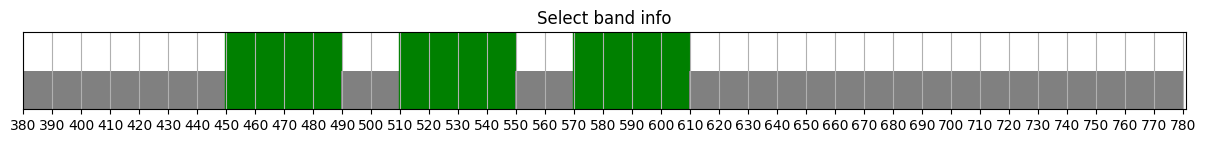

In [14]:
image_path = r'C:\Users\Arvind\Downloads\ColonoscopicDS_2016_WL\WLI\valid\Serrated'
nbi_path = r'C:\Users\Arvind\Downloads\ColonoscopicDS_2016_WL\Band_All\valid\Serrated'

gain = 2.5
is_normalize = False
filter_band = np.arange(450, 490, 1)
filter_band = np.append(filter_band, np.arange(510, 550, 1))
filter_band = np.append(filter_band, np.arange(570, 610, 1))
display_band_selected(filter_band)

In [16]:
if not os.path.isdir(nbi_path):
    os.makedirs(nbi_path)

for filename in os.listdir(image_path):
    file = os.path.join(image_path,filename)
    name = file.split('.')[0]
    
    img = cv2.imread(file)
     
    if img is not None:
        img = cv2.resize(img, (640, 640))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        spec = transfer.transfer(img)
        
        nbi = reproducer.reproduce(spec, gain, is_normalize, filter_band)
        nbi = cv2.cvtColor(nbi, cv2.COLOR_RGB2BGR)

        tar_file = os.path.join(nbi_path, filename)
        cv2.imwrite(tar_file, nbi)

# Single Transfer

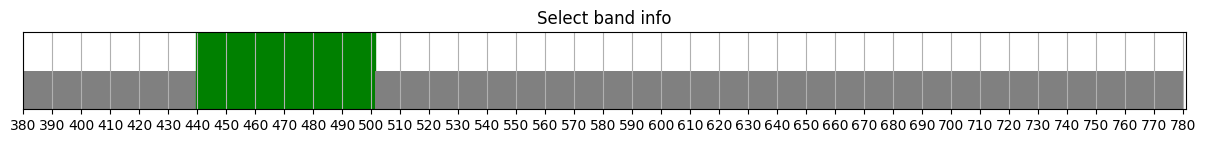

In [ ]:
# image_file = 'img.bmp'
image_file = 'E:\Projects\Ongoing\SAVE_Results\Skin Cancer\BCC, SCC, SK, AK\Classification\Dataset\skin_cancer_wli\BCC\ISIC_0001149.jpg'
nbi_file = 'E:\Projects\Ongoing\SAVE_Results\Skin Cancer\BCC, SCC, SK, AK\Classification\Dataset\skin_cancer_wli\BCC\123.jpg'

gain = 2
is_normalize = False
filter_band = np.arange(440, 502, 1)
#filter_band = np.append(filter_band, np.arange(685, 715, 1))
#filter_band = np.append(filter_band, np.arange(755, 780, 1))
#filter_band = np.append(filter_band, np.arange(610, 625, 1))
#filter_band = np.append(filter_band, np.arange(465, 495, 1))
#filter_band = np.append(filter_band, np.arange(515, 555, 1))
#filter_band = np.append(filter_band, np.arange(505, 555, 1))
display_band_selected(filter_band)

In [ ]:
img = cv2.imread(image_file)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

spec = transfer.transfer(img/255)

nbi = reproducer.reproduce(spec, gain, is_normalize, filter_band)
# nbi = predict(nbi)

nbi_bgr = cv2.cvtColor(nbi, cv2.COLOR_RGB2BGR)

cv2.imwrite(nbi_file, nbi_bgr)

MemoryError: Unable to allocate 11.2 GiB for an array with shape (3748096, 401) and data type float64

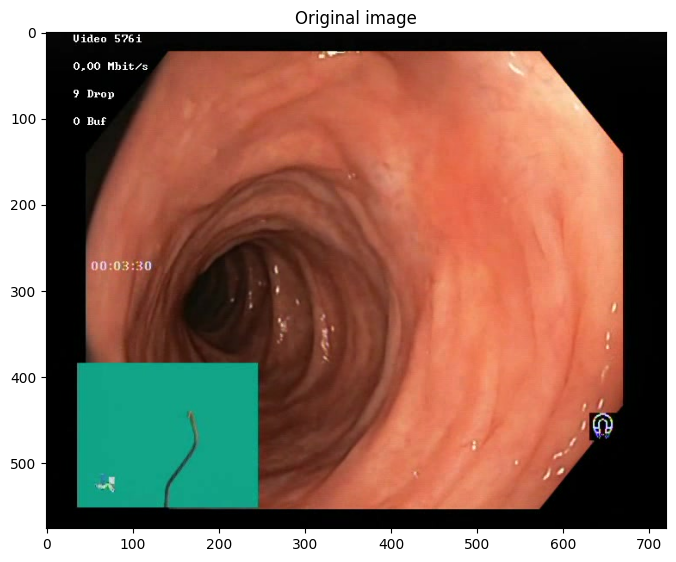

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Original image')
plt.show()

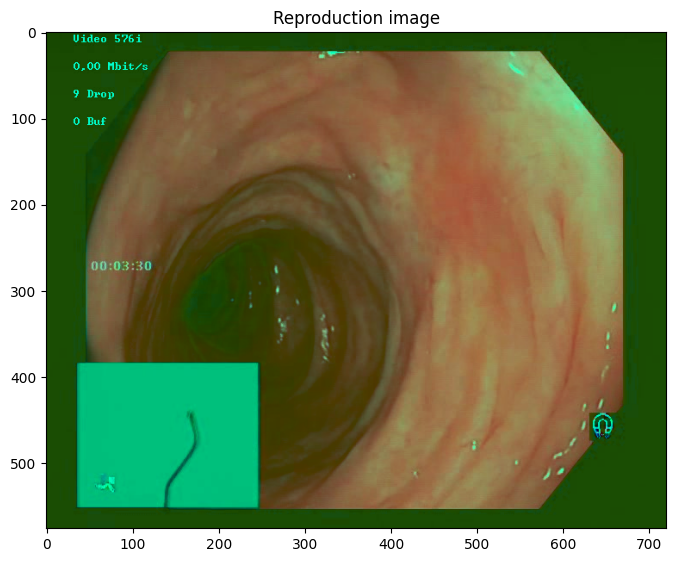

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(nbi)
plt.title('Reproduction image')
plt.show()

In [ ]:
cv2.imwrite('nbi.jpg', nbi)

True

In [ ]:
def gammaCurve(frame, gamma = 1):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = pow(i / 255, 1 / gamma) * 255
    return cv2.LUT(frame, look_up_table)

def sToneCurve(frame):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = 255 * (np.sin(np.pi * (i/255 - 1/2)) + 1) / 2
    return cv2.LUT(frame, look_up_table)

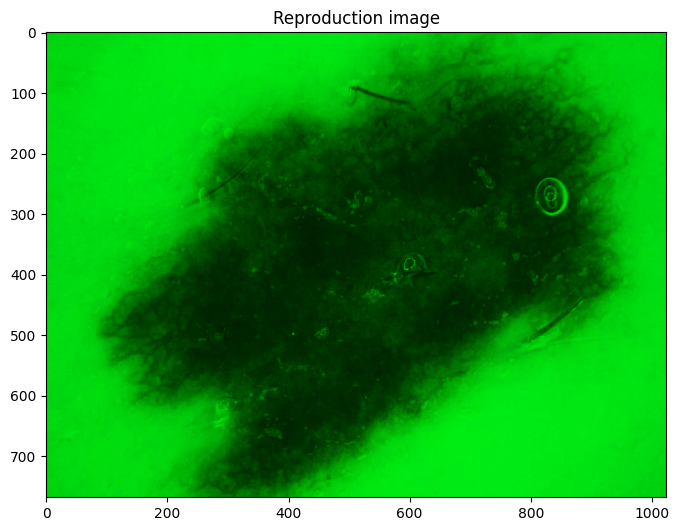

In [ ]:
test = sToneCurve(nbi)

plt.figure(figsize=(8, 8))
plt.imshow(test)
plt.title('Reproduction image')
plt.show()

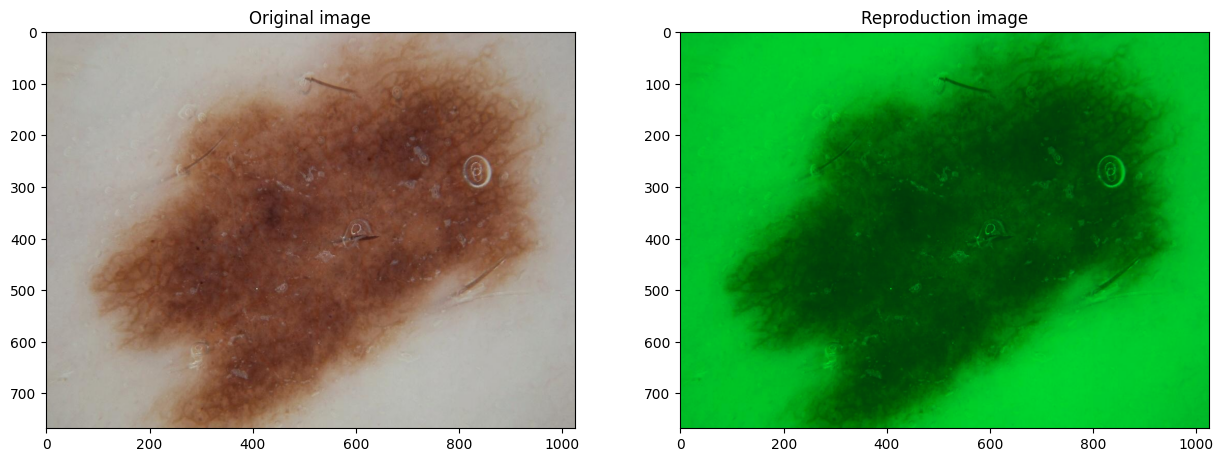

In [ ]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(nbi)
plt.title('Reproduction image')

plt.show()

In [ ]:
file_train_color_data = '24_color_sRGB.txt'

train_color = np.loadtxt(file_train_color_data).T

In [ ]:
c0 = train_color

spec = transfer.transfer(c0/255)
print('spec shape', spec.shape)

aaaa = np.expand_dims(spec, axis=0)

c1 = reproducer.reproduce(aaaa, 1.0, False)

c1 = c1[0,:,:]

spec shape (24, 401)


In [ ]:
from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000
from skimage.color import rgb2lab, lab2rgb

def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src)
    lab_test = rgb2lab(rgb_test)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

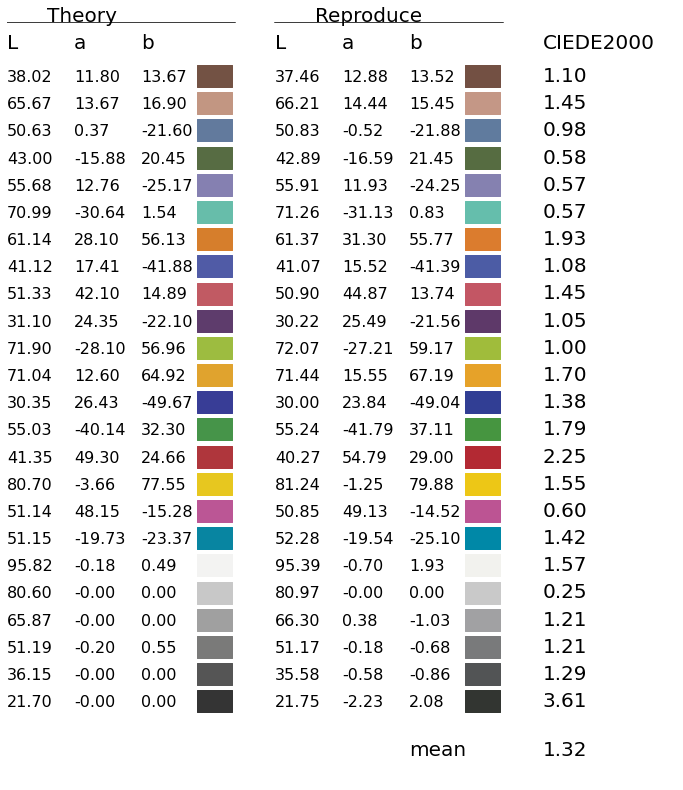

In [ ]:
rgb1 = c0.astype('uint8')
rgb2 = c1.astype('uint8')

lab1 = rgb2lab(rgb1)
lab2 = rgb2lab(rgb2)

errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)

plt.figure(figsize=(12, 14))
plt.axis('off')
plt.xlim(0, 50)
plt.ylim(-2, 26)

plt.plot([0,17], [26,26], 'k')
plt.annotate('Theory', (3, 26), fontsize = 20)
plt.annotate('L', (0, 25), fontsize = 20)
plt.annotate('a', (5, 25), fontsize = 20)
plt.annotate('b', (10, 25), fontsize = 20)

plt.plot([20,37], [26,26], 'k')
plt.annotate('Reproduce', (23, 26), fontsize = 20)
plt.annotate('L', (20, 25), fontsize = 20)
plt.annotate('a', (25, 25), fontsize = 20)
plt.annotate('b', (30, 25), fontsize = 20)

plt.annotate('CIEDE2000', (40, 25), fontsize = 20)

plt.annotate('mean', (30, -1), fontsize = 20)
plt.annotate('%.2f' %(np.mean(errs)), (40, -1), fontsize = 20)


for i in range(24):

    now_c1 = rgb1[i,:]
    now_c2 = rgb2[i,:]

    plt.scatter([15], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([16], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([35], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    plt.scatter([36], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    
    plt.annotate('%.2f' %(lab1[i,0]), (0, 24 - i - 0.2), fontsize = 16)
    plt.annotate('%.2f' %(lab1[i,1]), (5, 24 - i - 0.2), fontsize = 16)
    plt.annotate('%.2f' %(lab1[i,2]), (10, 24 - i - 0.2), fontsize = 16)

    plt.annotate('%.2f' %(lab2[i,0]), (20, 24 - i - 0.2), fontsize = 16)
    plt.annotate('%.2f' %(lab2[i,1]), (25, 24 - i - 0.2), fontsize = 16)
    plt.annotate('%.2f' %(lab2[i,2]), (30, 24 - i - 0.2), fontsize = 16)

    plt.annotate('%.2f' %(errs[i]), (40, 24 - i - 0.2), fontsize = 20)

plt.show()

In [ ]:
wlis = np.load('data_wli.npy')
wlis = train_color

spec = transfer.transfer(wlis/255)
print('spec shape', spec.shape)

aaaa = np.expand_dims(spec, axis=0)

nbi = reproducer.reproduce(aaaa, 1.0, False)

nbi = nbi[0,:,:]

spec shape (24, 401)


In [ ]:
from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000
from skimage.color import rgb2lab, lab2rgb

def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src)
    lab_test = rgb2lab(rgb_test)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

In [ ]:
def plot_diff(rgb1, rgb2):
    
    rgb1 = rgb1.astype('uint8')
    rgb2 = rgb2.astype('uint8')
    
    errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)
    
    plt.figure(figsize=(4, 14))
    plt.axis('off')
    plt.xlim(0, 30)
    plt.ylim(-2, 26)

    plt.annotate('c1.', (8, 25), fontsize = 20)
    plt.annotate('c2.', (16, 25), fontsize = 20)
    plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

    plt.annotate('mean', (16, -1), fontsize = 20)
    plt.annotate('%.2f' %(np.mean(errs)), (26, -1), fontsize = 20)

    plt.annotate('rmse', (16, -2), fontsize = 20)
    plt.annotate('%.2f' %(rmse(errs)), (26, -2), fontsize = 20)
    
    for i in range(24):

        now_c1 = rgb1[i,:]
        now_c2 = rgb2[i,:]

        plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
        plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))

        plt.annotate('%.2f' %(errs[i]), (26, 24 - i - 0.2), fontsize = 20)

    plt.show()

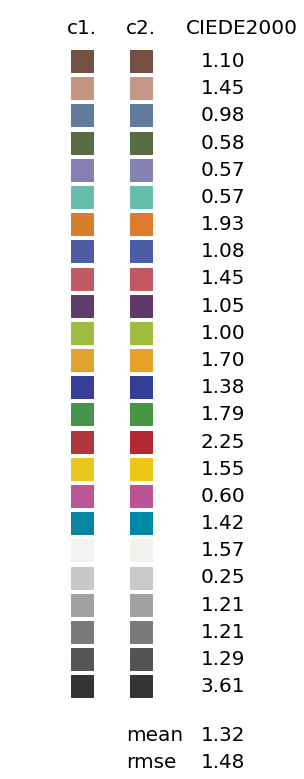

In [ ]:
plot_diff(wlis, nbi)

In [ ]:
np.save('nbi_org.npy', nbi)

# Test Region sample
+ rgb_image > hsi > operated image(nbi, adjust lighting...)
+ if we got hsi info, we can change lighting, cmf or just use mask to create narrow band image
+ this sample try get original image data and hsi data, show how to access the data we have
+ source data:
+ 1. img: original image data
+ 2. spec: spectrum data from our transfer
+ design parameters region roi with x, y, width, height

In [ ]:
# setup region info, we want to access this region data
reg_x = 200
reg_w = 5
reg_y = 300
reg_h = 5

print('print original data shape:')
print('img shape', img.shape)
print('spec shape', spec.shape)

# access region data
region_img = img[reg_y:reg_y+reg_h,reg_x:reg_x+reg_w,:]
region_sepc = spec[reg_y:reg_y+reg_h,reg_x:reg_x+reg_w,:]

print('print region data shape:')
print('region_img shape', region_img.shape)
print('region_sepc shape', region_sepc.shape)

print original data shape:
img shape (501, 575, 3)
spec shape (501, 575, 401)
print region data shape:
region_img shape (5, 5, 3)
region_sepc shape (5, 5, 401)


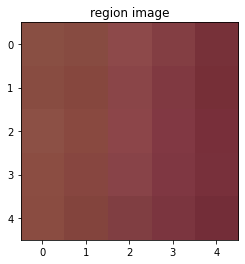

In [ ]:
# show region image we take
plt.figure(figsize=(4, 4))
plt.imshow(region_img )
plt.title('region image')
plt.show()

region_sepc_flat shape (25, 401)


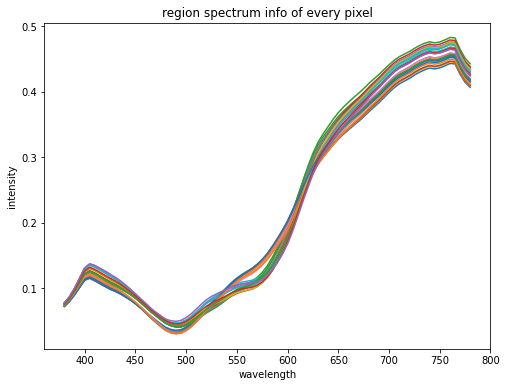

In [ ]:
# show region spectrum we take

# we have data with 3 dim.
# flatten spatial dim. 
# data shape will change to (w x h, c), 2 dim.

region_sepc_flat = region_sepc.reshape(-1,region_sepc.shape[2])
print('region_sepc_flat shape', region_sepc_flat.shape)


x = np.arange(380, 781, 1)

plt.figure(figsize=(8, 6))
plt.title('region spectrum info of every pixel')
plt.xlabel('wavelength')
plt.ylabel('intensity')

for i in range(region_sepc_flat.shape[0]):
    plt.plot(x, region_sepc_flat[i,:])

plt.show()

In [ ]:
def modify_contrast(img, brightness=0 , contrast=100):
    import math
    
    contrast = -30

    B = brightness / 255.0
    c = contrast / 255.0 
    k = math.tan((45 + 44 * c) / 180 * math.pi)

    img = (img - 127.5 * (1 - B)) * k + 127.5 * (1 + B)
      
    # 所有值必須介於 0~255 之間，超過255 = 255，小於 0 = 0
    img = np.clip(img, 0, 255).astype(np.uint8)

    return img
def modify_lightness(img):

    origin_img = img

    # 圖像歸一化，且轉換為浮點型
    fImg = img.astype(np.float32)
    fImg = fImg / 255.0

    # 顏色空間轉換 BGR -> HLS
    hlsImg = cv2.cvtColor(fImg, cv2.COLOR_RGB2HLS)
    hlsCopy = np.copy(hlsImg)

    lightness =80 # lightness 調整為  "1 +/- 幾 %"

    # 亮度調整
    hlsCopy[:, :, 1] = (1 + lightness / 100.0) * hlsCopy[:, :, 1]
    hlsCopy[:, :, 1][hlsCopy[:, :, 1] > 1] = 1  # 應該要介於 0~1，計算出來超過1 = 1

    # 顏色空間反轉換 HLS -> BGR 
    result_img = cv2.cvtColor(hlsCopy, cv2.COLOR_HLS2RGB)
    result_img = ((result_img * 255).astype(np.uint8))
    return result_img

In [ ]:
test_img = modify_lightness(nbi_bgr)
test_img = modify_contrast(test_img)

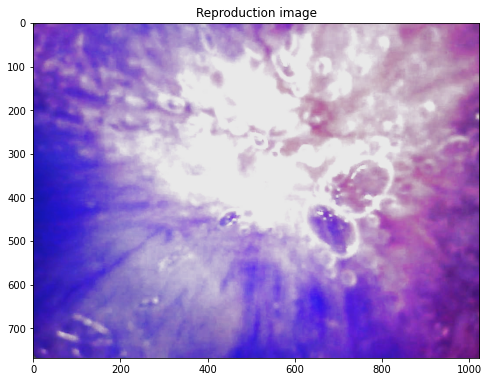

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(test_img)
plt.title('Reproduction image')
plt.show()

In [ ]:
a = np.arange(380,400,1)
b = np.arange(500,600,1)
np.concatenate((a,b))

In [ ]:
np.concatenate((a,b))

array([380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392,
       393, 394, 395, 396, 397, 398, 399, 500, 501, 502, 503, 504, 505,
       506, 507, 508, 509, 510, 511, 512, 513, 514, 515, 516, 517, 518,
       519, 520, 521, 522, 523, 524, 525, 526, 527, 528, 529, 530, 531,
       532, 533, 534, 535, 536, 537, 538, 539, 540, 541, 542, 543, 544,
       545, 546, 547, 548, 549, 550, 551, 552, 553, 554, 555, 556, 557,
       558, 559, 560, 561, 562, 563, 564, 565, 566, 567, 568, 569, 570,
       571, 572, 573, 574, 575, 576, 577, 578, 579, 580, 581, 582, 583,
       584, 585, 586, 587, 588, 589, 590, 591, 592, 593, 594, 595, 596,
       597, 598, 599])

In [ ]:
class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v) * 255.0
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0 * 255.0
        
        max_v = img_rep_xyz.max()
        
        if max_v > 255.0:
            img_rep_xyz = img_rep_xyz / max_v * 255.0
        
        img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
                
        img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
        return img_rep_rgb

In [ ]:
file_train_spec_data = '24_color_spectrum.txt'
file_train_color_data = '24_color_sRGB.txt'

train_spec = np.loadtxt(file_train_spec_data).T
print('train_spec shape', train_spec.shape)

train_color = np.loadtxt(file_train_color_data).T
print('train_color shape', train_color.shape)

train_spec shape (24, 401)
train_color shape (24, 3)


In [ ]:
spec = transfer.transfer(train_color/255)
print('spec shape', spec.shape)

spec shape (24, 401)


In [ ]:
aaaa = np.expand_dims(spec, axis=0)

nbi = reproducer.reproduce(aaaa, 1.0, False, None)

nbi = nbi[0,:,:]

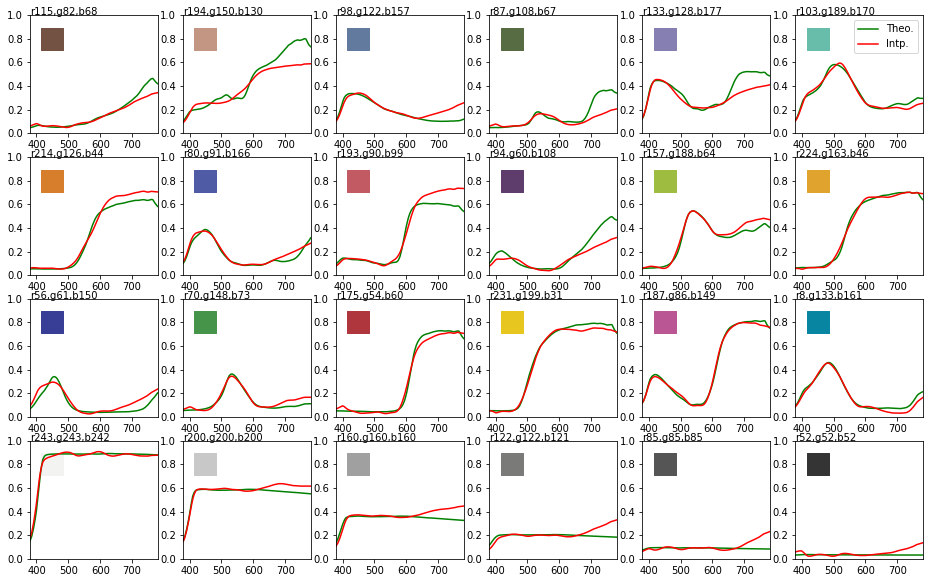

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10))

x = np.arange(380, 781, 1)

for i in range(24):
    
    now_c = train_color[i,:]
    
    plt.subplot(4,6,i+1)
    plt.xlim(380, 780)
    plt.ylim(0, 1)
    
    plt.plot(x, train_spec[i,:], 'g')
    plt.plot(x, spec[i,:], 'r')
    
    plt.annotate('r%d,g%d,b%d'%(now_c[0],now_c[1],now_c[2]), (380, 1.0))
    
    if i==5:
        plt.legend(['Theo.', 'Intp.'])
    
    plt.scatter([450], [0.8], marker='s', s = 500, color = (now_c[0]/255, now_c[1]/255, now_c[2]/255))
    
    
plt.show()

In [ ]:
np.savetxt("py_spec.csv", spec.T, delimiter=",")

In [ ]:
from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

def sepc_to_lab(spec_data, cmf, light_spec_x3, k):
    
    xyz_data = sepc_to_xyz(spec_data, cmf, light_spec_x3, k) / 100.0
    
    lab_data = np.zeros(xyz_data.shape)
    
    for i in range(xyz_data.shape[0]):
        xyz = XYZColor(xyz_data[i,0], xyz_data[i,1], xyz_data[i,2])

        lab = convert_color(xyz, LabColor)
        
        lab_data[i,0] = lab.lab_l
        lab_data[i,1] = lab.lab_a
        lab_data[i,2] = lab.lab_b
        
    return lab_data

def cal_delta_e_cie2000(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def sepc_to_xyz(train_spec, cmf, light_spec_x3, k):
    return np.dot(train_spec, cmf * light_spec_x3) * k    

In [ ]:
d65 = np.array([0.95047, 1.00000000, 1.08883])

cmf = np.loadtxt('cmf.txt')
light_spec = np.loadtxt('D65.txt')
ma = np.loadtxt('ma.txt')

light_spec_x3 = np.array([light_spec,light_spec,light_spec]).T 
cal_fact = cmf * light_spec_x3
k = 100.0 / sum(cal_fact[:,1])
white_light_k = np.dot(cmf.T, light_spec) * (k / 100.0)

In [ ]:
lab0 = sepc_to_lab(train_spec, cmf, light_spec_x3, k)
lab1 = sepc_to_lab(spec, cmf, light_spec_x3, k)
errs1 = cal_delta_e_cie2000(lab0, lab1)

In [ ]:
errs1

array([1.85712845, 2.18278688, 0.47542805, 0.79228825, 0.58358813,
       0.58929813, 0.6913682 , 0.40284439, 0.86350787, 1.18671066,
       0.41022932, 0.46041362, 0.57502482, 1.10257838, 1.925211  ,
       0.29975381, 0.13778058, 0.37854868, 0.42163955, 0.21355337,
       0.56618408, 0.85493005, 0.93244992, 3.9131109 ])

In [ ]:
np.mean(errs1)

0.909014878905649

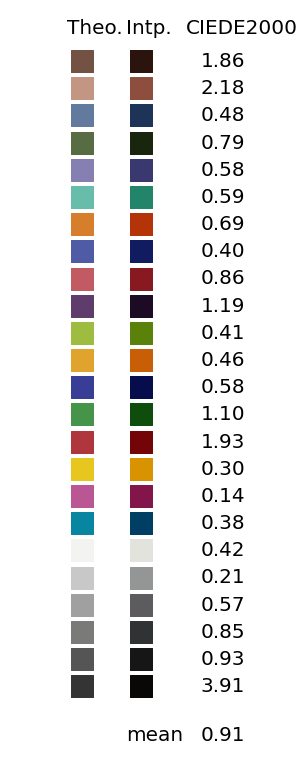

In [ ]:
plt.figure(figsize=(4, 14))
plt.axis('off')
plt.xlim(0, 30)
plt.ylim(-2, 26)



plt.annotate('Theo.', (8, 25), fontsize = 20)
plt.annotate('Intp.', (16, 25), fontsize = 20)
plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

plt.annotate('mean', (16, -1), fontsize = 20)

plt.annotate('%.2f' %(np.mean(errs1)), (26, -1), fontsize = 20)

for i in range(24):
    
    now_c = train_color[i,:]
    now_n = nbi[i,:]

    plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c[0]/255, now_c[1]/255, now_c[2]/255))
    plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_n[0]/255, now_n[1]/255, now_n[2]/255))
    
    plt.annotate('%.2f' %(errs1[i]), (26, 24 - i - 0.2), fontsize = 20)

plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error
import math

MSE = mean_squared_error(spec, train_spec)
RMSE = math.sqrt(MSE)

print('MSE', MSE)
print('RMSE', RMSE)

MSE 0.0023979234813475713
RMSE 0.04896859688971669


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BSpline, make_interp_spline

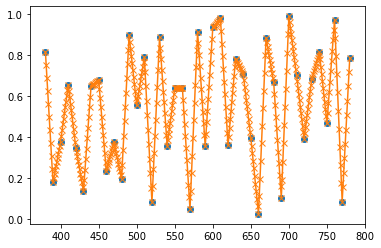

In [ ]:
x = np.arange(380,781,10)
y = np.random.rand(41)

xvals = np.arange(380,781)
yinterp = np.interp(xvals, x, y)

plt.plot(x, y, 'o')
plt.plot(xvals, yinterp, '-x')
plt.show()

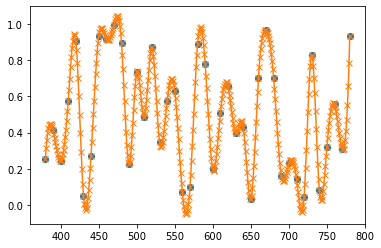

In [ ]:
x = np.arange(380,781,10)
y = np.random.rand(41)

spl = make_interp_spline(x, y)

x_new = np.arange(380,781)
y_new = spl(x_new).T

plt.plot(x, y, 'o')
plt.plot(x_new, y_new, '-x')
plt.show()

In [ ]:
x = np.arange(380,781,10)


In [ ]:
x.shape

(41,)

In [ ]:
def interp_light(light_spec_10nm):
    
    x = np.arange(380,781,10)
    
    xvals = np.arange(380,781)
    
    light_spec_1nm = np.interp(xvals, x, light_spec_10nm)  
    
    return light_spec_1nm

In [ ]:
interp_light(np.random.rand(41))

array([0.96972682, 0.95170523, 0.93368365, 0.91566207, 0.89764049,
       0.8796189 , 0.86159732, 0.84357574, 0.82555415, 0.80753257,
       0.78951099, 0.80596924, 0.82242749, 0.83888574, 0.85534399,
       0.87180224, 0.88826049, 0.90471874, 0.92117699, 0.93763524,
       0.95409349, 0.89273924, 0.83138499, 0.77003074, 0.70867649,
       0.64732224, 0.58596799, 0.52461375, 0.4632595 , 0.40190525,
       0.340551  , 0.39551924, 0.45048749, 0.50545574, 0.56042398,
       0.61539223, 0.67036048, 0.72532872, 0.78029697, 0.83526522,
       0.89023346, 0.88502737, 0.87982127, 0.87461518, 0.86940908,
       0.86420299, 0.85899689, 0.8537908 , 0.8485847 , 0.84337861,
       0.83817251, 0.79698121, 0.75578991, 0.71459861, 0.67340731,
       0.632216  , 0.5910247 , 0.5498334 , 0.5086421 , 0.46745079,
       0.42625949, 0.46317137, 0.50008325, 0.53699513, 0.57390701,
       0.61081888, 0.64773076, 0.68464264, 0.72155452, 0.7584664 ,
       0.79537828, 0.80374089, 0.8121035 , 0.82046611, 0.82882